# Wo schadet die μ̂-TTA — und wann sollte sie aufhören?

Zwei Fragen:

1. **Bei welchen Fällen schadet die TTA?** Geprüfte Hypothesen:
   * **H1** — sie schadet Fällen, die vorher schon gut waren (hoher Ausgangs-Dice),
   * **H2** — sie schadet dort, wo der Head schon vorher falsch lag (μ̂₀ ≠ Dice₀).
2. **Welche Stopping-Rule?** Bisher: feste Schrittzahl. Gesucht ist eine label-freie Regel, die
   ohne domänenspezifisches Tuning funktioniert.

**Daten.** μ̂-TTA mit pre-norm-Head, Affine an [0, 17], 5 Predictoren × 3 PMRI-Shifts (Testdomäne).
Zwei Läufe mit identischem Setup: **100 Schritte** (mit κ- und Logit-Drift-Verläufen) und
**1000 Schritte** (nur Dice und μ̂ pro Schritt). Die ersten 100 Schritte beider Läufe stimmen bis
auf Rauschen überein (mittlere Abweichung < 0.01 Dice). Fälle × Predictoren gepoolt.

**Geschädigt** = Dice am Ende mehr als 0.05 unter dem Ausgangswert, **verbessert** = mehr als
0.05 darüber.

### Kurzfassung

* **H1 (gute Fälle werden geschädigt) stimmt nur teilweise.** Fälle mit Ausgangs-Dice < 0.25
  werden praktisch nie geschädigt (nichts zu verlieren). Auf 3T→1.5T und PROMISE12 trifft der
  Schaden vor allem Fälle ab 0.5, und je länger man adaptiert, desto mehr (3T→1.5T, ≥ 0.75:
  12 % nach 100, 80 % nach 1000 Schritten). Auf 1.5T→3T ist es umgekehrt: Dort trifft es die
  Fälle bei 0.25–0.50, gute Fälle fast nie.
* **H2 (Schaden dort, wo μ̂₀ ≠ Dice₀) stimmt in der einfachen Form nicht** (AUROC von |μ̂₀ − Dice₀|
  0.53–0.62), **wohl aber mit Richtung:** Unter den guten Fällen werden die geschädigt, die der
  Head *unterschätzt* (3T→1.5T: 20 % vs. 5 %; PROMISE12: 11 % vs. 4 %). Er „hält“ eine gute Maske
  für schlecht und schiebt sie weg.
* **Schaden ist für den Head unsichtbar.** 76–93 % der geschädigten Fälle werden ab dem ersten
  Schritt schlechter, während μ̂ für sie um +0.12 bis +0.22 steigt. Früher μ̂-Anstieg sagt
  *Verbesserung* gut voraus (AUROC ≈ 0.8), *Schaden* nicht (≈ 0.5).
* **Folge für das Stoppen:** Eine Stopping-Rule kann nur den späten Schaden (Überschießen)
  verhindern, nicht den, der sofort einsetzt.
* **Empfehlung: μ̂-Plateau-Regel pro Fall** — anhalten, sobald μ̂ über 10 Schritte um weniger als
  0.01 steigt. Mit **einem** Parameter für alle Domänen liegt sie innerhalb von 0.005 Dice an der
  jeweils besten festen Schrittzahl, mit weniger Schaden (4.5 / 2.9 / 2.1 % statt 7.0 / 3.7 / 2.5 %),
  weniger Schaden in der Quelldomäne, ohne Horizont-Wahl, und sie funktioniert unverändert auch
  mit dem post-norm-Head.
* **Intuitive „Vertrauensbereich“-Regeln scheitern** (μ̂-Budget Δμ̂ ≥ δ, Credible Interval
  verlassen): Sie stoppen genau die Fälle früh, die sich verbessern, und lassen die anderen bis zum
  Ende laufen.

In [1]:
import glob, os, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import beta as Beta
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression

ROOT = os.path.abspath("../../../..")  # repo root
DOMAINS = {"threet-to-onepointfivet": "3T → 1.5T", "promise12": "PROMISE12",
           "onepointfivet-to-threet": "1.5T → 3T"}
RUNS = {100: "latent_tta_prenorm", 1000: "latent_tta_1000_steps"}
TOL = 0.05
INK2, MUTED, GRID, AXIS = "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
GROUP_COLOUR = {"verbessert": "#2a78d6", "unverändert": MUTED, "geschädigt": "#e34948"}
RULE_COLOUR = {"feste Schrittzahl": "#52514e", "μ̂-Plateau": "#2a78d6", "μ̂-Budget Δμ̂ ≥ δ": "#eb6834",
               "Credible-Interval verlassen": "#1baf7a"}
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9.5, "axes.titlesize": 10.5, "axes.titleweight": "bold",
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "lines.linewidth": 2, "legend.frameon": False,
})
pd.set_option("display.precision", 3)


def load(folder, d, split="test"):
    parts = []
    for p in range(5):
        path = glob.glob(f"{ROOT}/results/{folder}/pmri_{d}_*cleanHalf_{p}_*/latent_tta.pkl")[0]
        with open(path, "rb") as f:
            ev = pickle.load(f)["evaluation"][f"{d}_{split}"]
        parts.append({k: ev[k].float().numpy() for k in
                      ("dice_per_step", "mu_per_step", "kappa_before", "kappa_per_step", "logit_drift_per_step")
                      if ev.get(k) is not None} | {"predictor": np.full(len(ev["dice_before"]), p)})
    return {k: np.concatenate([x[k] for x in parts]) for k in parts[0]}


P = {(T, d): load(f, d) for T, f in RUNS.items() for d in DOMAINS}
PV = {(T, d): load(f, d, "val") for T, f in RUNS.items() for d in DOMAINS}
print({DOMAINS[d]: len(P[100, d]["dice_per_step"]) for d in DOMAINS}, "Fälle × Predictoren")

{'3T → 1.5T': 2405, 'PROMISE12': 6240, '1.5T → 3T': 5605} Fälle × Predictoren


In [2]:
def case_table(T, d, t=-1):
    x = P[T, d]
    D, M = x["dice_per_step"], x["mu_per_step"]
    delta = D[:, t] - D[:, 0]
    group = np.where(delta > TOL, "verbessert", np.where(delta < -TOL, "geschädigt", "unverändert"))
    k0 = x["kappa_before"]
    return pd.DataFrame({"D0": D[:, 0], "mu0": M[:, 0], "e0": M[:, 0] - D[:, 0], "kappa0": k0,
                         "sigma0": np.sqrt(M[:, 0] * (1 - M[:, 0]) / (k0 + 1)),
                         "delta": delta, "group": group, "predictor": x["predictor"]})

## 1 · Wie viel Schaden, und wie hängt er von der Laufzeit ab?

In [3]:
rows = []
for T in RUNS:
    for d, dl in DOMAINS.items():
        c = case_table(T, d)
        rows.append({"Schritte": T, "Domäne": dl, "ΔDice": c.delta.mean(),
                     **{g: (c.group == g).mean() for g in GROUP_COLOUR}})
display(pd.DataFrame(rows).set_index(["Schritte", "Domäne"]).style
        .format("{:.1%}", subset=list(GROUP_COLOUR)).format("{:+.3f}", subset=["ΔDice"]))

**Befund.** Nach 100 Schritten werden 11 / 5 / 3 % der Fälle geschädigt, nach 1000 Schritten
61 / 12 / 3 %. Auf 3T→1.5T kippt der Gesamteffekt von +0.076 auf −0.106. Wie schnell der Schaden
wächst, hängt also stark von der Domäne ab — genau das macht eine feste Schrittzahl fragwürdig.

## 2 · H1 und H2: Ausgangs-Dice und Fehlkalibrierung

Beide Größen hängen zusammen: Der Head schätzt gute Fälle eher zu niedrig und schlechte eher zu
hoch ein (Regression zur Mitte; Korrelation Dice₀ ↔ μ̂₀ − Dice₀ zwischen −0.3 und −0.8). Um sie zu
trennen, ist die Schadensquote **innerhalb** jedes Bins des Ausgangs-Dice nach dem Kalibrierfehler
e₀ = μ̂₀ − Dice₀ in Terzile aufgeteilt: *unterschätzt* (μ̂₀ zu niedrig) · *mittel* · *überschätzt*.

In [4]:
BINS = [(0, .25), (.25, .5), (.5, .75), (.75, 1.01)]
BIN_LABEL = ["< 0.25", "0.25–0.50", "0.50–0.75", "≥ 0.75"]


def strat(T):
    rows = []
    for d, dl in DOMAINS.items():
        c = case_table(T, d)
        for (lo, hi), bl in zip(BINS, BIN_LABEL):
            b = c[(c.D0 >= lo) & (c.D0 < hi)]
            row = {"Domäne": dl, "Ausgangs-Dice": bl, "n": len(b), "geschädigt (alle)": (b.group == "geschädigt").mean()}
            if len(b) >= 50:
                terc = pd.qcut(b.e0, 3, labels=["unterschätzt", "mittel", "überschätzt"])
                for t in ["unterschätzt", "mittel", "überschätzt"]:
                    row[f"geschädigt | {t}"] = (b.group[terc == t] == "geschädigt").mean()
                    row[f"verbessert | {t}"] = (b.group[terc == t] == "verbessert").mean()
            rows.append(row)
    return pd.DataFrame(rows).set_index(["Domäne", "Ausgangs-Dice"])


for T in RUNS:
    print(f"{T} Schritte")
    t = strat(T)
    display(t.style.format("{:.0%}", subset=[c for c in t.columns if c != "n"], na_rep="–"))

100 Schritte


1000 Schritte


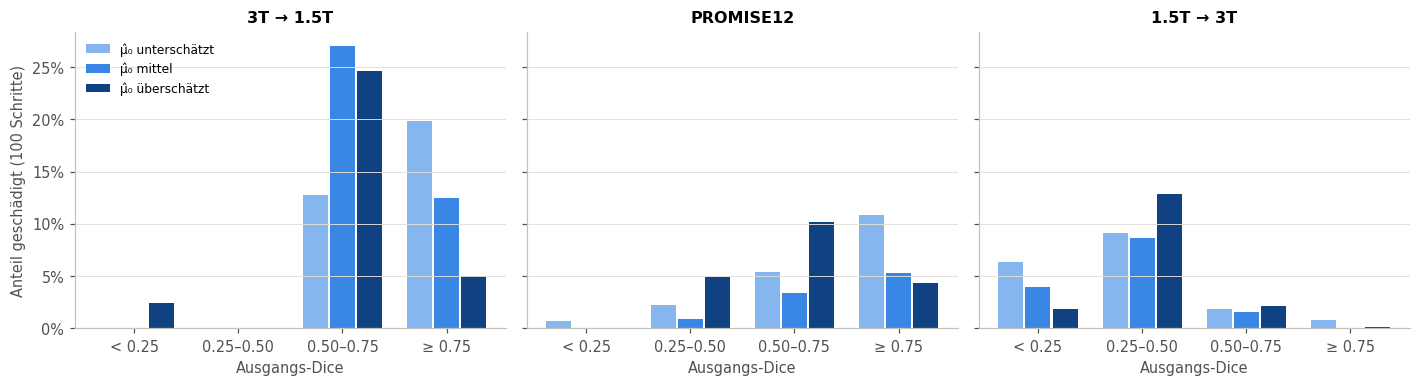

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
t = strat(100)
for ax, (d, dl) in zip(axes, DOMAINS.items()):
    sub = t.loc[dl]
    x = np.arange(len(sub))
    for k, (name, col) in enumerate(zip(["unterschätzt", "mittel", "überschätzt"], ["#86b6ef", "#3987e5", "#104281"])):
        ax.bar(x + (k - 1) * 0.26, sub[f"geschädigt | {name}"].fillna(0), width=0.24, color=col, label=f"μ̂₀ {name}")
    ax.set_xticks(x, sub.index); ax.set_title(dl); ax.set_xlabel("Ausgangs-Dice")
    ax.grid(axis="x", visible=False)
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
axes[0].set_ylabel("Anteil geschädigt (100 Schritte)")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Wie gut sagen die Größen Schaden voraus?** AUROC für „geschädigt“ (0.5 = Zufall; < 0.5 heißt:
*kleinere* Werte gehen mit Schaden einher). Dazu eine logistische Regression mit beiden
standardisierten Größen gemeinsam, und eine nur mit label-freien Größen (μ̂₀, log κ₀) — nur diese
wären im Einsatz verfügbar.

In [6]:
rows = []
for T in RUNS:
    for d, dl in DOMAINS.items():
        c = case_table(T, d)
        y = (c.group == "geschädigt").values
        z = lambda X: (X - X.mean(0)) / X.std(0)
        both = LogisticRegression().fit(z(c[["D0", "e0"]].values), y)
        X_lf = z(np.c_[c.mu0, np.log(c.kappa0)])
        lf = LogisticRegression().fit(X_lf, y)
        rows.append({"Schritte": T, "Domäne": dl,
                     "AUROC Dice₀ (H1)": roc_auc_score(y, c.D0),
                     "AUROC e₀ = μ̂₀−Dice₀": roc_auc_score(y, c.e0),
                     "AUROC |e₀| (H2)": roc_auc_score(y, c.e0.abs()),
                     "Koef. Dice₀ (gemeinsam)": both.coef_[0, 0], "Koef. e₀ (gemeinsam)": both.coef_[0, 1],
                     "AUROC label-frei (μ̂₀, κ₀)": roc_auc_score(y, lf.decision_function(X_lf))})
display(pd.DataFrame(rows).set_index(["Schritte", "Domäne"]).style.format(precision=2))

**Befund H1 (Ausgangs-Dice).**
* Fälle mit Dice₀ < 0.25 werden fast nie geschädigt (0–4 %), sie können nur gewinnen.
* 3T→1.5T und PROMISE12: Der Schaden sitzt bei Dice₀ ≥ 0.5 (3T→1.5T: 22 % bzw. 12 % nach 100
  Schritten, 62 % bzw. 80 % nach 1000). AUROC von Dice₀ für Schaden: 0.58–0.61 nach 100, 0.82 nach
  1000 Schritten auf 3T→1.5T.
* 1.5T→3T: umgekehrt (AUROC 0.35–0.40). Der Schaden sitzt bei 0.25–0.50 (10 %), Fälle ≥ 0.75
  bleiben fast immer unverändert.
* → H1 stimmt für Domänen, in denen die TTA viel bewegt, und wird mit der Laufzeit stärker. Als
  allgemeine Regel taugt es nicht.

**Befund H2 (Fehlkalibrierung).**
* Der Betrag |μ̂₀ − Dice₀| sagt Schaden kaum voraus (AUROC 0.53–0.62).
* Die **Richtung** zählt, und zwar je nach Ausgangsniveau unterschiedlich:
  * gute Fälle (≥ 0.75): Schaden vor allem bei **Unterschätzung** (3T→1.5T 20 % vs. 5 %,
    PROMISE12 11 % vs. 4 %),
  * mittlere Fälle (PROMISE12 0.25–0.75, 1.5T→3T 0.25–0.50): eher bei **Überschätzung** (5–13 % vs. 2–9 %).
* Unterschätzte mittlere Fälle profitieren am meisten (3T→1.5T, 0.50–0.75: 79 % verbessert vs.
  39 % bei Überschätzung): Wo der Head „zu pessimistisch“ ist, hat der Gradient Platz.
* Gemeinsam mit Dice₀ in einer Regression trägt e₀ auf 3T→1.5T / PROMISE12 kaum noch etwas bei
  (Koeffizient −0.02 / −0.19 vs. 0.65 / 0.62 für Dice₀). Der Gesamtzusammenhang mit e₀ ist großteils
  der Zusammenhang mit Dice₀ (Regression zur Mitte).

**Label-frei** (μ̂₀, κ₀) lässt sich Schaden nur schwach vorhersagen (AUROC 0.56–0.77). Ein Gate
*vor* der Adaption kann ihn also nicht zuverlässig verhindern.

## 3 · Wie sieht Schaden im Verlauf aus — und sieht der Head ihn?

Mittlere Verläufe von echtem Dice (durchgezogen) und μ̂ (gestrichelt), getrennt nach dem
Endzustand nach 100 Schritten, jeweils relativ zum Startwert.

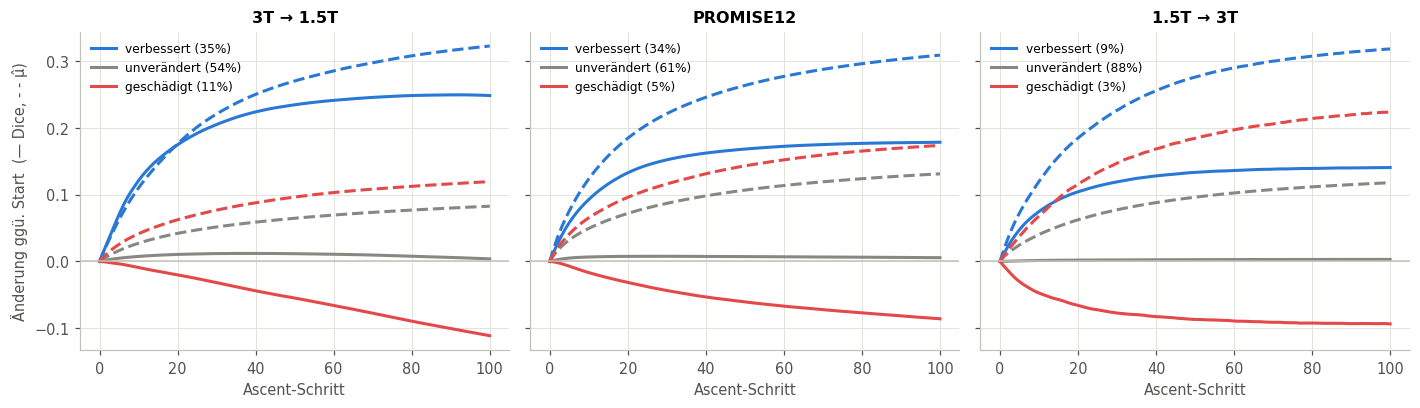

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, (d, dl) in zip(axes, DOMAINS.items()):
    c = case_table(100, d); x = P[100, d]
    D, M = x["dice_per_step"], x["mu_per_step"]
    for g, col in GROUP_COLOUR.items():
        m = (c.group == g).values
        ax.plot((D[m] - D[m, :1]).mean(0), color=col, label=f"{g} ({m.mean():.0%})")
        ax.plot((M[m] - M[m, :1]).mean(0), color=col, ls="--")
    ax.axhline(0, color=AXIS, lw=1)
    ax.set_title(dl); ax.set_xlabel("Ascent-Schritt")
    ax.legend(fontsize=8, loc="upper left")
axes[0].set_ylabel("Änderung ggü. Start  (— Dice, - - μ̂)")
plt.tight_layout(); plt.show()

In [8]:
rows = []
for T in RUNS:
    for d, dl in DOMAINS.items():
        c = case_table(T, d); x = P[T, d]
        D, M = x["dice_per_step"], x["mu_per_step"]
        h = (c.group == "geschädigt").values
        if h.sum() < 20:
            continue
        cross = np.array([np.argmax(r < r[0] - TOL) for r in D[h]])
        rows.append({"Schritte": T, "Domäne": dl, "geschädigt": h.mean(),
                     "davon nie > Start + 0.01": ((D[h].max(1) - D[h, 0]) < 0.01).mean(),
                     "davon erst verbessert, dann geschädigt": ((D[h].max(1) - D[h, 0]) > TOL).mean(),
                     "Schritt, ab dem geschädigt (Median)": np.median(cross),
                     "Δμ̂ geschädigt": (M[h, -1] - M[h, 0]).mean(),
                     "Δμ̂ verbessert": (M[(c.group == "verbessert").values, -1] - M[(c.group == "verbessert").values, 0]).mean()})
display(pd.DataFrame(rows).set_index(["Schritte", "Domäne"]).style.format(precision=3)
        .format("{:.0%}", subset=["geschädigt", "davon nie > Start + 0.01", "davon erst verbessert, dann geschädigt"])
        .format("{:.0f}", subset=["Schritt, ab dem geschädigt (Median)"]))

**Lässt sich Schaden früh label-frei erkennen?** AUROC von Signalen nach 10 Schritten, einmal für
„wird geschädigt“, einmal für „wird verbessert“ (100-Schritt-Lauf).

In [9]:
rows = []
for d, dl in DOMAINS.items():
    c = case_table(100, d); x = P[100, d]
    M, K, L = x["mu_per_step"], x["kappa_per_step"], x["logit_drift_per_step"]
    sig = {"Δμ̂ nach 10": M[:, 10] - M[:, 0], "Δ log κ nach 10": np.log(K[:, 10] / K[:, 0]),
           "Logit-Drift nach 10": L[:, 10]}
    for name, v in sig.items():
        rows.append({"Domäne": dl, "Signal": name,
                     "AUROC geschädigt": roc_auc_score(c.group == "geschädigt", v),
                     "AUROC verbessert": roc_auc_score(c.group == "verbessert", v)})
display(pd.DataFrame(rows).set_index(["Domäne", "Signal"]).unstack("Domäne").style.format(precision=2))

In [10]:
rows = []
for T in RUNS:
    for d, dl in DOMAINS.items():
        c = case_table(T, d)
        H = np.stack([(c.group == "geschädigt").values[c.predictor == p] for p in range(5)])
        cond = np.mean([(H[p] & H[q]).sum() / max(H[p].sum(), 1) for p in range(5) for q in range(5) if p != q])
        rows.append({"Schritte": T, "Domäne": dl, "Schadensquote": H.mean(),
                     "P(geschädigt bei Predictor B | geschädigt bei A)": cond,
                     "Fälle, die ≥ 1 Predictor schädigt": (H.sum(0) >= 1).mean(),
                     "Fälle, die alle 5 schädigen": (H.sum(0) == 5).mean()})
display(pd.DataFrame(rows).set_index(["Schritte", "Domäne"]).style.format("{:.1%}"))

**Befund.**
* **Schaden setzt sofort ein.** 76–93 % der nach 100 Schritten geschädigten Fälle sind zu keinem
  Zeitpunkt besser als der Start; nur 0–4 % verbessern sich erst und kippen dann. Erst bei sehr
  langer Adaption kommt Überschießen dazu (3T→1.5T, 1000 Schritte: 29 %).
* **Der Head sieht es nicht.** Für geschädigte Fälle steigt μ̂ trotzdem um +0.12 bis +0.22
  (verbesserte: +0.31). Der μ̂-Anstieg nach 10 Schritten sagt Verbesserung gut vorher (AUROC 0.80–0.81),
  Schaden nicht (0.48–0.61). κ und Logit-Drift helfen ebenso wenig.
* **Schaden ist überwiegend predictor-spezifisch.** Schädigt Predictor A einen Fall, tut es ein
  anderer Predictor B nur in 30–46 % der Fälle (Grundrate 3–11 %); von allen fünf geschädigt werden
  nur 0.1–1.5 % der Fälle (100 Schritte). Ausnahme: sehr lange Adaption auf 3T→1.5T (30 %).
  Das spricht dafür, dass der Schaden aus den Schwächen des jeweiligen Heads kommt, nicht aus dem
  Bild — und dass ein *zweiter*, nicht optimierter Head ihn bemerken könnte (noch nicht getestet).

## 4 · Stopping-Rules

Alle Regeln entscheiden **pro Fall** und nur aus Größen, die ohne Labels verfügbar sind. Sie
werden offline auf den gespeicherten Verläufen simuliert: Für jede Regel wird der Schritt
bestimmt, an dem sie anhalten würde, und der Dice an diesem Schritt genommen.

| Regel | hält an, sobald … | Parameter | Idee |
|---|---|---|---|
| **feste Schrittzahl** | t = T | T | Status quo |
| **μ̂-Budget** | μ̂ₜ − μ̂₀ ≥ δ | δ | „nicht mehr als δ Verbesserung glauben“ (`stop_rule: delta-mu-target`) |
| **Credible-Interval verlassen** | μ̂ₜ > oberes α-Quantil von Beta(μ̂₀, κ₀) | α | Vertrauensbereich aus der *eigenen* Anfangsunsicherheit |
| **μ̂-Plateau** | μ̂ über die letzten w = 10 Schritte um < ε gestiegen | ε | klassisches Early Stopping: Ziel konvergiert |
| κ-Wachstum | κₜ / κ₀ ≥ c | c | „Head wird verdächtig sicher“ (nur 100-Schritt-Lauf) |
| Logit-Drift | mittleres \|Logits − Logits₀\| ≥ c | c | Änderungsbudget für die Maske (nur 100-Schritt-Lauf) |

Bewertet auf dem **1000-Schritt-Lauf**: Eine Regel muss dort von selbst anhalten, sonst läuft sie
in den Bereich, in dem der Schaden dominiert.

In [11]:
def first_true(cond, default):
    return np.where(cond.any(1), cond.argmax(1), default)


def rule_stop(x, rule, th):
    D, M = x["dice_per_step"], x["mu_per_step"]
    last = D.shape[1] - 1
    if rule == "feste Schrittzahl":
        return np.full(len(D), min(th, last))
    if rule == "μ̂-Budget Δμ̂ ≥ δ":
        return first_true(M - M[:, :1] >= th, last)
    if rule == "Credible-Interval verlassen":
        m0, k0 = np.clip(M[:, 0], 1e-4, 1 - 1e-4), x["kappa_before"]
        hi = Beta.ppf(th, m0 * k0, (1 - m0) * k0)
        return first_true(M >= hi[:, None], last)
    if rule == "μ̂-Plateau":
        g = np.full(M.shape, np.inf); g[:, 10:] = M[:, 10:] - M[:, :-10]
        return first_true(g < th, last)
    if rule == "κ-Wachstum":
        K = x["kappa_per_step"]; return first_true(K / K[:, :1] >= th, last)
    if rule == "Logit-Drift":
        return first_true(x["logit_drift_per_step"] >= th, last)


def outcome(x, stop):
    D = x["dice_per_step"]
    delta = D[np.arange(len(D)), stop] - D[:, 0]
    return {"ΔDice": delta.mean(), "geschädigt": (delta < -TOL).mean(), "verbessert": (delta > TOL).mean(),
            "Stopp-Schritt (Median)": np.median(stop),
            "Anteil am Fall-Optimum": delta.mean() / (D.max(1) - D[:, 0]).mean()}


GRID_ = {"feste Schrittzahl": [5, 10, 20, 30, 40, 50, 60, 75, 100, 150, 200, 300, 500, 1000],
         "μ̂-Plateau": [0.03, 0.02, 0.015, 0.01, 0.0075, 0.005, 0.003, 0.002, 0.001],
         "μ̂-Budget Δμ̂ ≥ δ": [0.02, 0.05, 0.075, 0.1, 0.15, 0.2, 0.3, 0.5],
         "Credible-Interval verlassen": [0.6, 0.7, 0.8, 0.9, 0.95, 0.99]}
SIM = pd.DataFrame([{"Regel": r, "Parameter": th, "Domäne": dl, **outcome(P[1000, d], rule_stop(P[1000, d], r, th)),
                     "ΔDice Quelldomäne (val)": outcome(PV[1000, d], rule_stop(PV[1000, d], r, th))["ΔDice"]}
                    for r, g in GRID_.items() for th in g for d, dl in DOMAINS.items()])

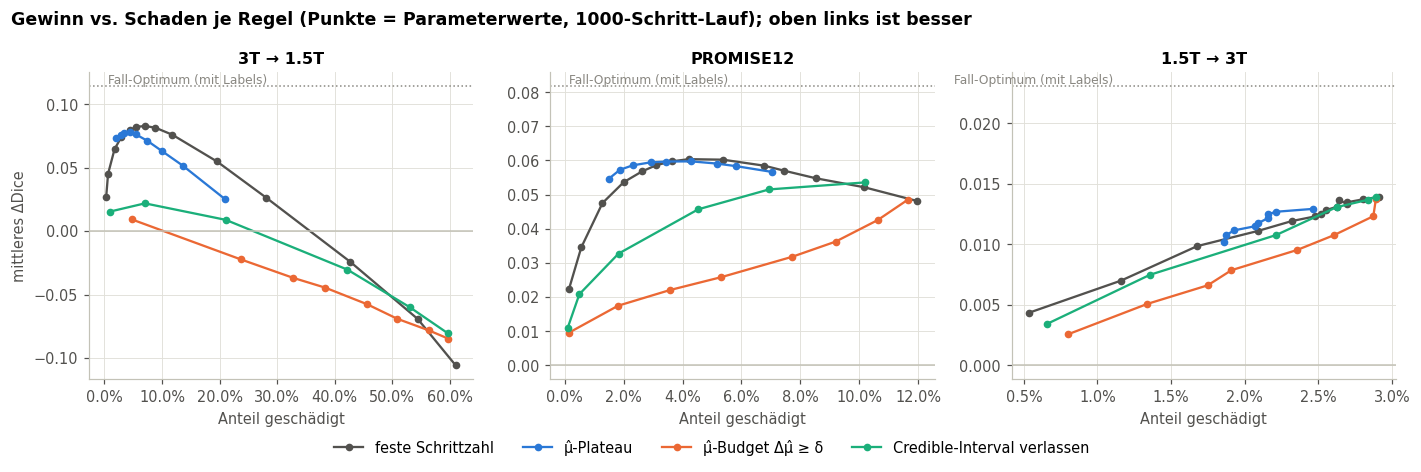

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=False)
for ax, dl in zip(axes, DOMAINS.values()):
    for r, col in RULE_COLOUR.items():
        s = SIM[(SIM.Regel == r) & (SIM.Domäne == dl)].sort_values("geschädigt")
        ax.plot(s["geschädigt"], s["ΔDice"], "-o", ms=4, lw=1.5, color=col, label=r)
    best = (P[1000, [d for d in DOMAINS if DOMAINS[d] == dl][0]]["dice_per_step"])
    ax.axhline((best.max(1) - best[:, 0]).mean(), color=MUTED, lw=1, ls=":")
    ax.text(0.0, (best.max(1) - best[:, 0]).mean(), " Fall-Optimum (mit Labels)",
            color=MUTED, fontsize=8, va="bottom")
    ax.axhline(0, color=AXIS, lw=1)
    ax.set_title(dl); ax.set_xlabel("Anteil geschädigt")
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=1))
axes[0].set_ylabel("mittleres ΔDice")
fig.legend(handles=axes[0].get_lines()[:len(RULE_COLOUR)], loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Gewinn vs. Schaden je Regel (Punkte = Parameterwerte, 1000-Schritt-Lauf); oben links ist besser",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

**Beste Einstellung je Regel**, gewählt nach dem mittleren ΔDice über alle drei Domänen
(ein Parameter für alle):

In [13]:
mean_ = SIM.groupby(["Regel", "Parameter"])["ΔDice"].mean()
best = mean_.groupby("Regel").idxmax()
rows = []
for r, (_, th) in best.items():
    s = SIM[(SIM.Regel == r) & (SIM.Parameter == th)].set_index("Domäne")
    rows.append({"Regel": r, "Parameter": f"{th:g}", **{f"ΔDice {dl}": s.loc[dl, "ΔDice"] for dl in DOMAINS.values()},
                 "ΔDice Mittel": mean_[r, th],
                 **{f"geschädigt {dl}": s.loc[dl, "geschädigt"] for dl in DOMAINS.values()},
                 "ΔDice Quelldomäne (val, Mittel)": s["ΔDice Quelldomäne (val)"].mean()})
ref = {"Regel": "Fall-Optimum (mit Labels)", "Parameter": "–"}
for d, dl in DOMAINS.items():
    D = P[1000, d]["dice_per_step"]; ref[f"ΔDice {dl}"] = (D.max(1) - D[:, 0]).mean()
ref["ΔDice Mittel"] = np.mean([ref[f"ΔDice {dl}"] for dl in DOMAINS.values()])
rows.append(ref)
best_tab = pd.DataFrame(rows).set_index("Regel")
display(best_tab.style.format(precision=3, na_rep="–")
        .format("{:.1%}", subset=[f"geschädigt {dl}" for dl in DOMAINS.values()], na_rep="–"))

,Parameter,ΔDice 3T → 1.5T,ΔDice PROMISE12,ΔDice 1.5T → 3T,ΔDice Mittel,geschädigt 3T → 1.5T,geschädigt PROMISE12,geschädigt 1.5T → 3T,"ΔDice Quelldomäne (val, Mittel)"
Regel,,,,,,,,,
Credible-Interval verlassen,0.8,0.009,0.033,0.011,0.017,21.1%,1.8%,2.2%,-0.029
feste Schrittzahl,60,0.083,0.060,0.013,0.052,7.0%,3.7%,2.5%,-0.009
μ̂-Budget Δμ̂ ≥ δ,0.02,0.009,0.010,0.003,0.007,4.7%,0.1%,0.8%,-0.013
μ̂-Plateau,0.01,0.078,0.059,0.011,0.050,4.5%,2.9%,2.1%,-0.003
Fall-Optimum (mit Labels),–,0.114,0.082,0.023,0.073,–,–,–,–


**Übertragbarkeit (Leave-one-domain-out):** Parameter auf zwei Domänen gewählt, auf der dritten
getestet — so, als käme eine neue Domäne hinzu.

In [14]:
rows = []
for r in GRID_:
    for d, dl in DOMAINS.items():
        others = [o for o in DOMAINS.values() if o != dl]
        s = SIM[SIM.Regel == r]
        th = s[s.Domäne.isin(others)].groupby("Parameter")["ΔDice"].mean().idxmax()
        hit = s[(s.Parameter == th) & (s.Domäne == dl)].iloc[0]
        opt = s[s.Domäne == dl]["ΔDice"].max()
        rows.append({"Regel": r, "Test-Domäne": dl, "gewählter Parameter": th, "ΔDice": hit["ΔDice"],
                     "Bestwert dieser Regel auf der Domäne": opt, "geschädigt": hit["geschädigt"]})
display(pd.DataFrame(rows).set_index(["Regel", "Test-Domäne"]).style.format(precision=3)
        .format("{:.1%}", subset=["geschädigt"]).format(lambda v: f"{v:g}", subset=["gewählter Parameter"]))

**κ-Wachstum und Logit-Drift** lassen sich nur auf dem 100-Schritt-Lauf auswerten (der 1000-Schritt-Lauf
hat diese Verläufe nicht gespeichert). Vergleich bei gleichem Horizont:

In [15]:
rows = []
for r, g in {"feste Schrittzahl": [20, 40, 60, 100], "μ̂-Plateau": [0.02, 0.01, 0.005],
             "κ-Wachstum": [1.5, 2, 3, 5], "Logit-Drift": [0.5, 1, 2]}.items():
    for th in g:
        row = {"Regel": r, "Parameter": f"{th:g}"}
        for d, dl in DOMAINS.items():
            o = outcome(P[100, d], rule_stop(P[100, d], r, th))
            row[f"ΔDice {dl}"] = o["ΔDice"]; row[f"geschädigt {dl}"] = o["geschädigt"]
        row["ΔDice Mittel"] = np.mean([row[f"ΔDice {dl}"] for dl in DOMAINS.values()])
        rows.append(row)
display(pd.DataFrame(rows).set_index(["Regel", "Parameter"]).style.format(precision=3)
        .format("{:.1%}", subset=[f"geschädigt {dl}" for dl in DOMAINS.values()]))

**Robustheit der Plateau-Regel** gegenüber der Fensterlänge w und dem Predictor-Typ: Schwelle als
Steigung (μ̂-Zuwachs pro Schritt), damit w frei wählbar ist. Zum Vergleich der Lauf mit
**post-norm-Head** (nur 100 Schritte).

In [16]:
def slope_stop(x, s, w):
    M = x["mu_per_step"]; g = np.full(M.shape, np.inf); g[:, w:] = (M[:, w:] - M[:, :-w]) / w
    return first_true(g < s, M.shape[1] - 1)


Ppost = {d: load("latent_tta_postnorm", d) for d in DOMAINS}
rows = []
for name, data in [("pre-norm, 1000 Schritte", {d: P[1000, d] for d in DOMAINS}), ("post-norm, 100 Schritte", Ppost)]:
    for w in (5, 10, 20):
        for s in (0.002, 0.001, 0.0005):
            row = {"Lauf": name, "w": w, "Steigung <": f"{s:g}"}
            for d, dl in DOMAINS.items():
                o = outcome(data[d], slope_stop(data[d], s, w))
                row[f"ΔDice {dl}"] = o["ΔDice"]; row[f"geschädigt {dl}"] = o["geschädigt"]
            rows.append(row)
    for T in (50, 100):
        row = {"Lauf": name, "w": "fest", "Steigung <": f"T={T}"}
        for d, dl in DOMAINS.items():
            o = outcome(data[d], np.full(len(data[d]["dice_per_step"]), min(T, data[d]["dice_per_step"].shape[1] - 1)))
            row[f"ΔDice {dl}"] = o["ΔDice"]; row[f"geschädigt {dl}"] = o["geschädigt"]
        rows.append(row)
display(pd.DataFrame(rows).set_index(["Lauf", "w", "Steigung <"]).style.format(precision=3)
        .format("{:.1%}", subset=[f"geschädigt {dl}" for dl in DOMAINS.values()]))

**Befund.**
* **μ̂-Budget und Credible-Interval-Regel funktionieren nicht.** Fälle, deren μ̂ schnell steigt, sind
  gerade die, die sich verbessern — die Regeln stoppen sie früh. Fälle, deren μ̂ langsam steigt
  (unverändert / geschädigt), erreichen das Budget nie und laufen bis zum Ende. Auf 3T→1.5T ist
  das bei übertragenem Parameter schlechter als gar nicht zu adaptieren (−0.085).
* **μ̂-Plateau (ε = 0.01 pro 10 Schritte)** erreicht +0.078 / +0.059 / +0.011, die beste *feste*
  Schrittzahl (T = 60, im Nachhinein gewählt) +0.083 / +0.060 / +0.013. Dabei:
  * weniger Schaden: 4.5 / 2.9 / 2.1 % statt 7.0 / 3.7 / 2.5 %,
  * weniger Schaden in der Quelldomäne: −0.003 statt −0.009,
  * Stopp-Schritt passt sich an (Median 28 / 39 / 24), kein Horizont muss gewählt werden;
    die Regel hält von selbst an, auch wenn man 1000 Schritte erlaubt.
* **Robust:** Als Steigung formuliert (0.001 μ̂ pro Schritt) ist das Ergebnis für Fensterlängen
  w = 5–20 praktisch gleich. Mit dem post-norm-Head liefert derselbe Parameter dasselbe wie T = 100.
* **κ-Wachstum und Logit-Drift** liegen nicht über der festen Schrittzahl bei gleichem Schaden; κ
  verhält sich zudem zwischen pre- und post-norm-Head völlig verschieden (Faktor 3–10), eine
  κ-Schwelle wäre nicht übertragbar.
* **Ehrlich gesagt:** Im Gewinn-vs.-Schaden-Bild liegt die Plateau-Regel *auf* der Kurve der
  festen Schrittzahl, nicht darüber. Ihr Wert ist, dass man den Punkt auf dieser Kurve nicht pro
  Domäne wählen muss. Auch übertragen (Leave-one-domain-out) liegen beide nah am Bestwert; die feste
  Schrittzahl wird dabei auf 3T→1.5T mit T = 100 gewählt und schädigt dort 11.8 % der Fälle.
* Zum Fall-Optimum (bester Schritt pro Fall, braucht Labels) bleibt eine Lücke (Mittel 0.050 vs.
  0.073). Sie besteht vor allem aus Fällen, die ab dem ersten Schritt schlechter werden — dort
  wäre „gar nicht adaptieren“ richtig, und das kann keine Stopping-Rule auf Basis von μ̂ erkennen.

## 5 · Fazit

1. **Schaden** trifft auf zwei Domänen vor allem gute und mittlere Fälle, besonders solche, die
   der Head unterschätzt. Er setzt meist sofort ein, ist für den Head unsichtbar und überwiegend
   predictor-spezifisch.
2. **Stopping-Rule-Vorschlag:** pro Fall anhalten, sobald μ̂ über 10 Schritte um weniger als 0.01
   steigt; dazu eine großzügige Obergrenze (z. B. 300 Schritte) als Sicherheitsnetz. Begründung
   nach außen: Standard-Early-Stopping auf der Zielfunktion, ein Parameter in μ̂-Einheiten, gleiche
   Einstellung für alle Domänen und beide Head-Varianten.
3. **Was die Regel nicht kann:** sofort einsetzenden Schaden verhindern. Dafür braucht es ein Signal,
   das nicht vom optimierten Head kommt. Naheliegender nächster Versuch: mit einem Predictor
   adaptieren und einen *anderen* (nicht im Gradienten) mitlaufen lassen; anhalten bzw. verwerfen,
   wenn dessen μ̂ fällt. Da der Schaden größtenteils predictor-spezifisch ist, hat das eine
   realistische Chance.
4. Alle Ergebnisse hier sind **Offline-Simulationen** auf gespeicherten Verläufen. Online
   (pro Bild Parameter einfrieren) muss die Plateau-Regel noch implementiert und bestätigt werden.